<a href="https://colab.research.google.com/github/limzhilit/ml-campus_data_project-colab/blob/main/ML_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Week 1

| Item | Details |
|-------|---------|
| Issue or Challenge Identified |Pull data from Excel as CSV file, prune empty rows and cols, and clean temperature data|
| Decision Taken |Imported the dataset into Python using Pandas, removed empty rows and columns, identified missing temperature values,<br> and replaced missing values with the mean temperature where appropriate. |
| Justification |Cleaning the dataset improves data quality and ensures that missing temperature values do not interfere with subsequent data analysis. <br>Using the mean preserves the dataset's size while providing reasonable estimates for missing values. |
| Evidence Supporting the Decision |Used Pandas functions such as pd.read_csv(), dropna(), isnull().sum(), and fillna() <br>to import, inspect, and clean the dataset. Checked the number of missing values before and after cleaning to verify the results. |
| Reflection |This task improved my understanding of data preprocessing and handling missing values using Python. <br>I learned that missing values should be investigated before deciding how to handle them, <br>as removing entire rows may result in losing useful information. <br>I also learned that using the mean can be appropriate for numerical temperature data, <br>although it may not always be suitable if the data contains outliers or is strongly skewed. |

Import CSV and libraries

In [149]:
# @title
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [150]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import data_table

In [151]:
df = pd.read_csv(
    '/content/drive/MyDrive/ML_lab/CampusWalkDataset_TemplateIDs.csv',
    skiprows=4,
    keep_default_na=False # to avoid loading None in as null
)



Setup the table library from Google Colab to show data more clearly


In [152]:
# Increase maximum displayed columns
data_table.DataTable.max_columns = 30

# DataFrame display settings
data_table.enable_dataframe_formatter()

Delete (empty/with only id row) and (col)

In [153]:
# Convert empty strings and whitespace-only cells into NaN
df = df.replace(r"^\s*$", pd.NA, regex=True)

# Remove completely empty columns
df = df.dropna(axis=1, how='all')

# Remove observations where all columns except recorder_id are empty
df = df.dropna(
    subset=df.columns.drop("recorder_id"),
    how="all"
)

# Reset row numbering
df = df.reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Exact duplicate rows:", df.duplicated().sum())

Dataset shape: (135, 23)
Exact duplicate rows: 0


In [154]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 135 entries, 0 to 134
Data columns (total 23 columns):
 #   Column                                 Non-Null Count  Dtype 
---  ------                                 --------------  ----- 
 0   recorder_id                            135 non-null    object
 1   date                                   135 non-null    object
 2   location                               135 non-null    object
 3   weather                                135 non-null    object
 4   temperature_c                          135 non-null    object
 5   sound level                            135 non-null    object
 6   foot_traffic                           135 non-null    object
 7   primary_sound_type_urban               135 non-null    object
 8   other_sound_type_urban                 132 non-null    object
 9   primary_sound_type_nature              135 non-null    object
 10  other_sound_type_nature                133 non-null    object
 1

Use heatmap to spot missing value instantly

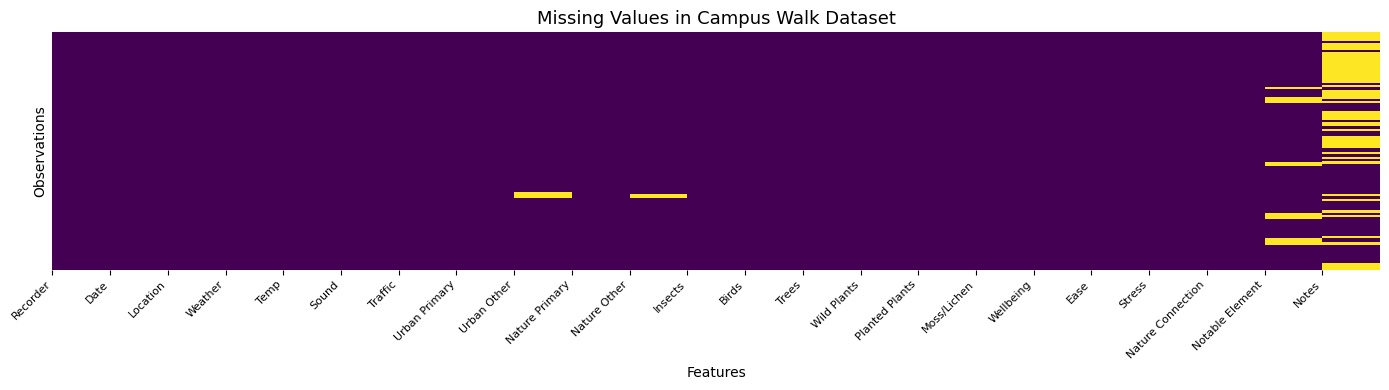

In [155]:
# @title
plt.figure(figsize=(14, 4))

ax = sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

short_labels = [
    "Recorder", "Date", "Location", "Weather", "Temp",
    "Sound", "Traffic", "Urban Primary", "Urban Other",
    "Nature Primary", "Nature Other", "Insects", "Birds",
    "Trees", "Wild Plants", "Planted Plants", "Moss/Lichen",
    "Wellbeing", "Ease", "Stress", "Nature Connection",
    "Notable Element", "Notes"
]

ax.set_xticks(range(len(short_labels)))
ax.set_xticklabels(short_labels, rotation=45, ha="right", fontsize=8)

plt.title("Missing Values in Campus Walk Dataset", fontsize=13)
plt.xlabel("Features")
plt.ylabel("Observations")

plt.tight_layout()
plt.show()

Count of missing cells

In [156]:
# @title
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values("Missing Percentage", ascending=False)

display(missing_summary)

,Missing Count,Missing Percentage
other_notes,65,48.15
most_notable_nature_element,13,9.63
other_sound_type_urban,3,2.22
other_sound_type_nature,2,1.48


Convert numeric columns to numeric data type

In [157]:
numerical_columns = [
    "temperature_c",
    "insects_count",
    "birds_count"
]

# Check numerical data quality
for col in numerical_columns:
    print(f"\n{col}")
    print("Data type:", df[col].dtype)
    print("Missing values:", df[col].isna().sum())
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print("Unique values:", sorted(df[col].dropna().unique()))


temperature_c
Data type: object
Missing values: 0
Minimum: 10
Maximum: 19C
Unique values: ['10', '13', '14', '15', '16', '16.5', '16C', '17', '17C', '18', '18C', '19', '19C']

insects_count
Data type: object
Missing values: 0
Minimum: 0
Maximum: 7
Unique values: ['0', '1', '10', '2', '20', '25', '26', '3', '31', '4', '5', '6', '7']

birds_count
Data type: object
Missing values: 0
Minimum: 0
Maximum: 6
Unique values: ['0', '1', '10', '12', '13', '2', '20', '3', '4', '5', '6']


Remove celcius unit from data, validate data range and convert to float

In [158]:
# Remove Celsius units and whitespace
df["temperature_c"] = (
    df["temperature_c"]
    .astype("string")
    .str.replace(r"[°Cc\s]", "", regex=True)
)

# Convert to numeric
df["temperature_c"] = pd.to_numeric(
    df["temperature_c"],
    errors="coerce"
)

# Define acceptable temperature range
MIN_TEMP = -5
MAX_TEMP = 40

# Identify potentially unrealistic temperatures
invalid_temp = df[
    (df["temperature_c"] < MIN_TEMP) |
    (df["temperature_c"] > MAX_TEMP)
]

display(invalid_temp[["recorder_id", "date", "location", "temperature_c"]])

,recorder_id,date,location,temperature_c


Convert insect and bird count to int




In [159]:
# @title
# Convert count columns to numeric
count_columns = ["insects_count", "birds_count"]

for col in count_columns:
    df[col] = pd.to_numeric(df[col])

# Verify data types
display(df[count_columns].dtypes.to_frame("Data Type"))

,Data Type
insects_count,int64
birds_count,int64


Categories data

In [160]:
# Environmental characteristics used for clustering
features = [
    "weather",
    "temperature_c",
    "sound level",
    "foot_traffic",
    "primary_sound_type_urban",
    "other_sound_type_urban",
    "primary_sound_type_nature",
    "other_sound_type_nature",
    "insects_count",
    "birds_count",
    "trees_presence",
    "native_or_wild_plant_presence",
    "ornnamental_or_planted_plant_presence",
    "moss_or_lichen_presence"
]

# Human-experience variables used to evaluate the clusters
outcome = [
    "wellbeing_rating",
    "ease_rating",
    "stress_rating",
    "nature_connection_experience_rating"
]

# Separate features and outcomes
X = df[features].copy()
y = df[outcome].copy()

print("Feature dimensions:", X.shape)
print("Outcome dimensions:", y.shape)

Feature dimensions: (135, 14)
Outcome dimensions: (135, 4)


In [161]:
# fix capitalisation and spelling issues, print all the unique values
# all_cols = features + outcome

# for col in all_cols:
#     print(f"\n{col}")
#     print(df[col].dropna().unique())

In [162]:
# Remove leading and trailing whitespace from categorical values
categorical_columns = df.select_dtypes(
    include=["object"]
).columns

for col in categorical_columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Correct known spelling and capitalisation inconsistencies
corrections = {
    "weather": {
        "sunny": "Sunny"
    },
    "foot_traffic": {
        "low": "Low"
    },
    "ease_rating": {
        "Vey easy": "Very easy",
        "Slighly uneasy": "Slightly uneasy"
    }
}
for col, mapping in corrections.items():
    df[col] = df[col].replace(mapping)

# Fix space inconsistencies
df["moss_or_lichen_presence"] = (
    df["moss_or_lichen_presence"].str.strip()
)

# Fix same category
df["nature_connection_experience_rating"] = (
    df["nature_connection_experience_rating"].replace({
        "same": "No change"
    })
)

In [163]:
for col in all_cols:
    print(f"\n{col}")
    print(df[col].dropna().unique())


weather
['Partly cloudy' 'Sunny' 'Windy' 'Cloudy']

temperature_c
<FloatingArray>
[16.0, 17.0, 19.0, 18.0, 15.0, 13.0, 16.5, 14.0, 10.0]
Length: 9, dtype: Float64

sound level
['Quiet' 'Moderate' 'Loud']

foot_traffic
['Low' 'Moderate' 'High']

primary_sound_type_urban
['Human voices' 'Traffic' 'Construction' 'Service machinery' 'Other']

other_sound_type_urban
['Traffic' 'Human voices' 'Other' 'Service machinery' 'Construction']

primary_sound_type_nature
['Wind' 'Other birds' 'Trees' 'Seagulls' 'Other' 'Insects']

other_sound_type_nature
['Trees' 'Other birds' 'Insects' 'Other' 'Wind' 'Seagulls']

insects_count
[ 0 10  2  7  3  6  1  5 31  4 26 20 25]

birds_count
[ 1  2 20  0  4  3 12 13 10  5  6]

trees_presence
['Many' 'One or two' 'None']

native_or_wild_plant_presence
['Some' 'None' 'Many']

ornnamental_or_planted_plant_presence
['Some' 'Many' 'None']

moss_or_lichen_presence
['Some' 'None' 'Many']

wellbeing_rating
['Positive wellbeing' 'Neutral' 'Very positive wellbeing'
 'Ve

In [164]:
X.dtypes

,0
weather,object
temperature_c,Float64
sound level,object
foot_traffic,object
primary_sound_type_urban,object
other_sound_type_urban,object
primary_sound_type_nature,object
other_sound_type_nature,object
insects_count,int64
birds_count,int64


# Encoding Data

| Feature type | Encoding method | Reason |
|---|---|---|
| Ordinal categorical | Ordinal encoding by mapping to numeric value | Preserves natural ordering |
| Nominal categorical | One-hot encoding with pd.get_dummies() | Avoids artificial ranking |
| Missing secondary sounds | Replace with `Not recorded` | Preserves observation meaning |
| Numerical features | Retain numerical values | Already machine-readable |



In [165]:
# Select environmental features only
X = df[features].copy()

# 1. Handle missing secondary sound observations
sound_cols = [
    "other_sound_type_urban",
    "other_sound_type_nature"
]

X[sound_cols] = X[sound_cols].fillna("Not recorded")

# 2. Ordinal encoding
ordinal_mappings = {
    "sound level": {
        "Quiet": 0,
        "Moderate": 1,
        "Loud": 2
    },
    "foot_traffic": {
        "Low": 0,
        "Moderate": 1,
        "High": 2
    },
    "trees_presence": {
        "None": 0,
        "One or two": 1,
        "Some": 2,
        "Many": 3
    },
    "native_or_wild_plant_presence": {
        "None": 0,
        "One or two": 1,
        "Some": 2,
        "Many": 3
    },
    "ornnamental_or_planted_plant_presence": {
        "None": 0,
        "One or two": 1,
        "Some": 2,
        "Many": 3
    },
    "moss_or_lichen_presence": {
        "None": 0,
        "One or two": 1,
        "Some": 2,
        "Many": 3
    }
}

for col, mapping in ordinal_mappings.items():
    X[col] = X[col].map(mapping)

# 3. One-hot encoding for nominal variables
nominal_cols = [
    "weather",
    "primary_sound_type_urban",
    "other_sound_type_urban",
    "primary_sound_type_nature",
    "other_sound_type_nature"
]

X = pd.get_dummies(
    X,
    columns=nominal_cols,
    dtype=int
)

# 4. Verify encoded dataset
print("Encoded dataset shape:", X.shape)

print("\nMissing values:")
print(X.isnull().sum().sum())

print("\nData types:")
print(X.dtypes.value_counts())

display(X.head())

Encoded dataset shape: (135, 37)

Missing values:
0

Data types:
int64      36
Float64     1
Name: count, dtype: int64


,temperature_c,sound level,foot_traffic,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,weather_Cloudy,...,primary_sound_type_nature_Seagulls,primary_sound_type_nature_Trees,primary_sound_type_nature_Wind,other_sound_type_nature_Insects,other_sound_type_nature_Not recorded,other_sound_type_nature_Other,other_sound_type_nature_Other birds,other_sound_type_nature_Seagulls,other_sound_type_nature_Trees,other_sound_type_nature_Wind
0,16.0,0,0,0,1,3,2,2,2,0,...,0,0,1,0,0,0,0,0,1,0
1,16.0,1,0,0,2,3,0,2,0,0,...,0,0,1,0,0,0,0,0,1,0
2,16.0,0,0,10,20,3,0,3,2,0,...,0,0,1,0,0,0,1,0,0,0
3,16.0,1,0,0,2,1,2,0,2,0,...,0,0,1,0,0,0,1,0,0,0
4,16.0,1,0,0,0,1,0,2,0,0,...,0,0,1,0,0,0,0,0,1,0


In [166]:
from sklearn.preprocessing import StandardScaler

# Identify numerical and ordinal columns
scale_cols = [
    "temperature_c",
    "sound level",
    "foot_traffic",
    "insects_count",
    "birds_count",
    "trees_presence",
    "native_or_wild_plant_presence",
    "ornnamental_or_planted_plant_presence",
    "moss_or_lichen_presence"
]

# Create a copy of the encoded dataset
X_scaled = X.copy()

# Standardise selected columns
scaler = StandardScaler()
X_scaled[scale_cols] = scaler.fit_transform(X_scaled[scale_cols])

# Verify scaling
display(X_scaled.head())

print("Dataset shape:", X_scaled.shape)
print("\nFeature means:")
print(X_scaled[scale_cols].mean().round(2))

print("\nFeature standard deviations:")
print(X_scaled[scale_cols].std().round(2))

,temperature_c,sound level,foot_traffic,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,weather_Cloudy,...,primary_sound_type_nature_Seagulls,primary_sound_type_nature_Trees,primary_sound_type_nature_Wind,other_sound_type_nature_Insects,other_sound_type_nature_Not recorded,other_sound_type_nature_Other,other_sound_type_nature_Other birds,other_sound_type_nature_Seagulls,other_sound_type_nature_Trees,other_sound_type_nature_Wind
0,-0.483562,-1.022948,-0.587805,-0.537246,-0.357106,0.56993,-0.190799,0.251775,0.252851,0,...,0,0,1,0,0,0,0,0,1,0
1,-0.483562,0.446180,-0.587805,-0.537246,0.002665,0.56993,-2.643925,0.251775,-1.543719,0,...,0,0,1,0,0,0,0,0,1,0
2,-0.483562,-1.022948,-0.587805,1.428288,6.478545,0.56993,-2.643925,1.123306,0.252851,0,...,0,0,1,0,0,0,1,0,0,0
3,-0.483562,0.446180,-0.587805,-0.537246,0.002665,-1.53803,-0.190799,-1.491285,0.252851,0,...,0,0,1,0,0,0,1,0,0,0
4,-0.483562,0.446180,-0.587805,-0.537246,-0.716877,-1.53803,-2.643925,0.251775,-1.543719,0,...,0,0,1,0,0,0,0,0,1,0


Dataset shape: (135, 37)

Feature means:
temperature_c                           -0.0
sound level                              0.0
foot_traffic                             0.0
insects_count                            0.0
birds_count                             -0.0
trees_presence                           0.0
native_or_wild_plant_presence            0.0
ornnamental_or_planted_plant_presence    0.0
moss_or_lichen_presence                 -0.0
dtype: float64

Feature standard deviations:
temperature_c                            1.0
sound level                              1.0
foot_traffic                             1.0
insects_count                            1.0
birds_count                              1.0
trees_presence                           1.0
native_or_wild_plant_presence            1.0
ornnamental_or_planted_plant_presence    1.0
moss_or_lichen_presence                  1.0
dtype: float64


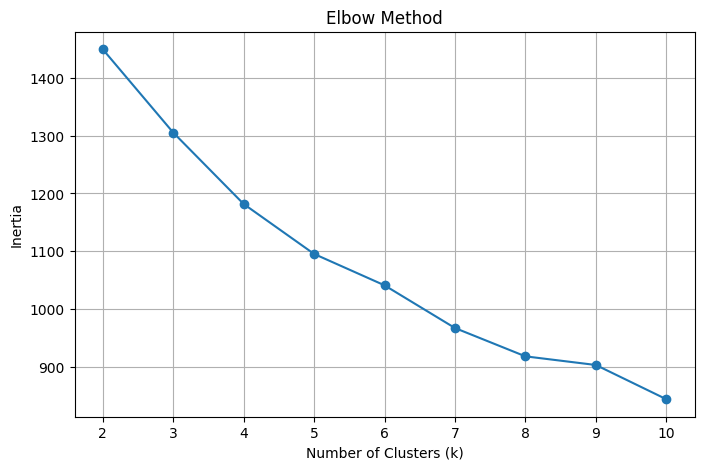

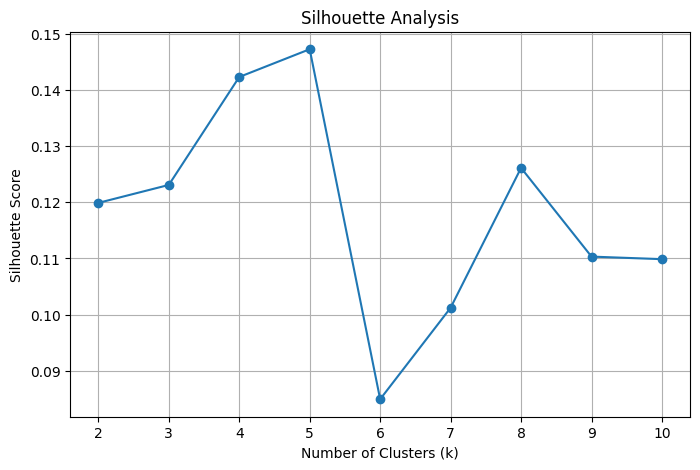

In [167]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Test different numbers of clusters
k_values = range(2, 11)

inertias = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

# Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(k_values)
plt.grid(True)
plt.show()

# Silhouette Score
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")
plt.xticks(k_values)
plt.grid(True)
plt.show()

In [168]:
from sklearn.cluster import KMeans

# Apply K-means clustering
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_scaled)

# Add cluster assignments to original dataset
df_clustered = df.copy()
df_clustered["cluster"] = cluster_labels

# Display cluster sizes
print("Cluster sizes:")
print(df_clustered["cluster"].value_counts().sort_index())

# Display cluster distribution
print("\nCluster percentages:")
print(
    (df_clustered["cluster"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

Cluster sizes:
cluster
0    32
1    67
2     4
3    32
Name: count, dtype: int64

Cluster percentages:
cluster
0    23.70
1    49.63
2     2.96
3    23.70
Name: proportion, dtype: float64


In [169]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

results = []

for k in range(2, 6):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    sizes = pd.Series(labels).value_counts()

    results.append({
        "Clusters": k,
        "Silhouette Score": round(
            silhouette_score(X_scaled, labels), 4
        ),
        "Smallest Cluster": sizes.min(),
        "Largest Cluster": sizes.max()
    })

results_df = pd.DataFrame(results)
display(results_df)


,Clusters,Silhouette Score,Smallest Cluster,Largest Cluster
0,2,0.1199,41,94
1,3,0.1231,32,67
2,4,0.1423,4,67
3,5,0.1473,4,66


In [170]:
# Select numerical environmental features
numerical_features = [
    "temperature_c",
    "insects_count",
    "birds_count"
]

# Calculate correlation matrix
correlation_matrix = df[numerical_features].corr(
    method="pearson"
)

display(correlation_matrix.round(2))

,temperature_c,insects_count,birds_count
temperature_c,1.00,-0.04,-0.04
insects_count,-0.04,1.00,0.43
birds_count,-0.04,0.43,1.00


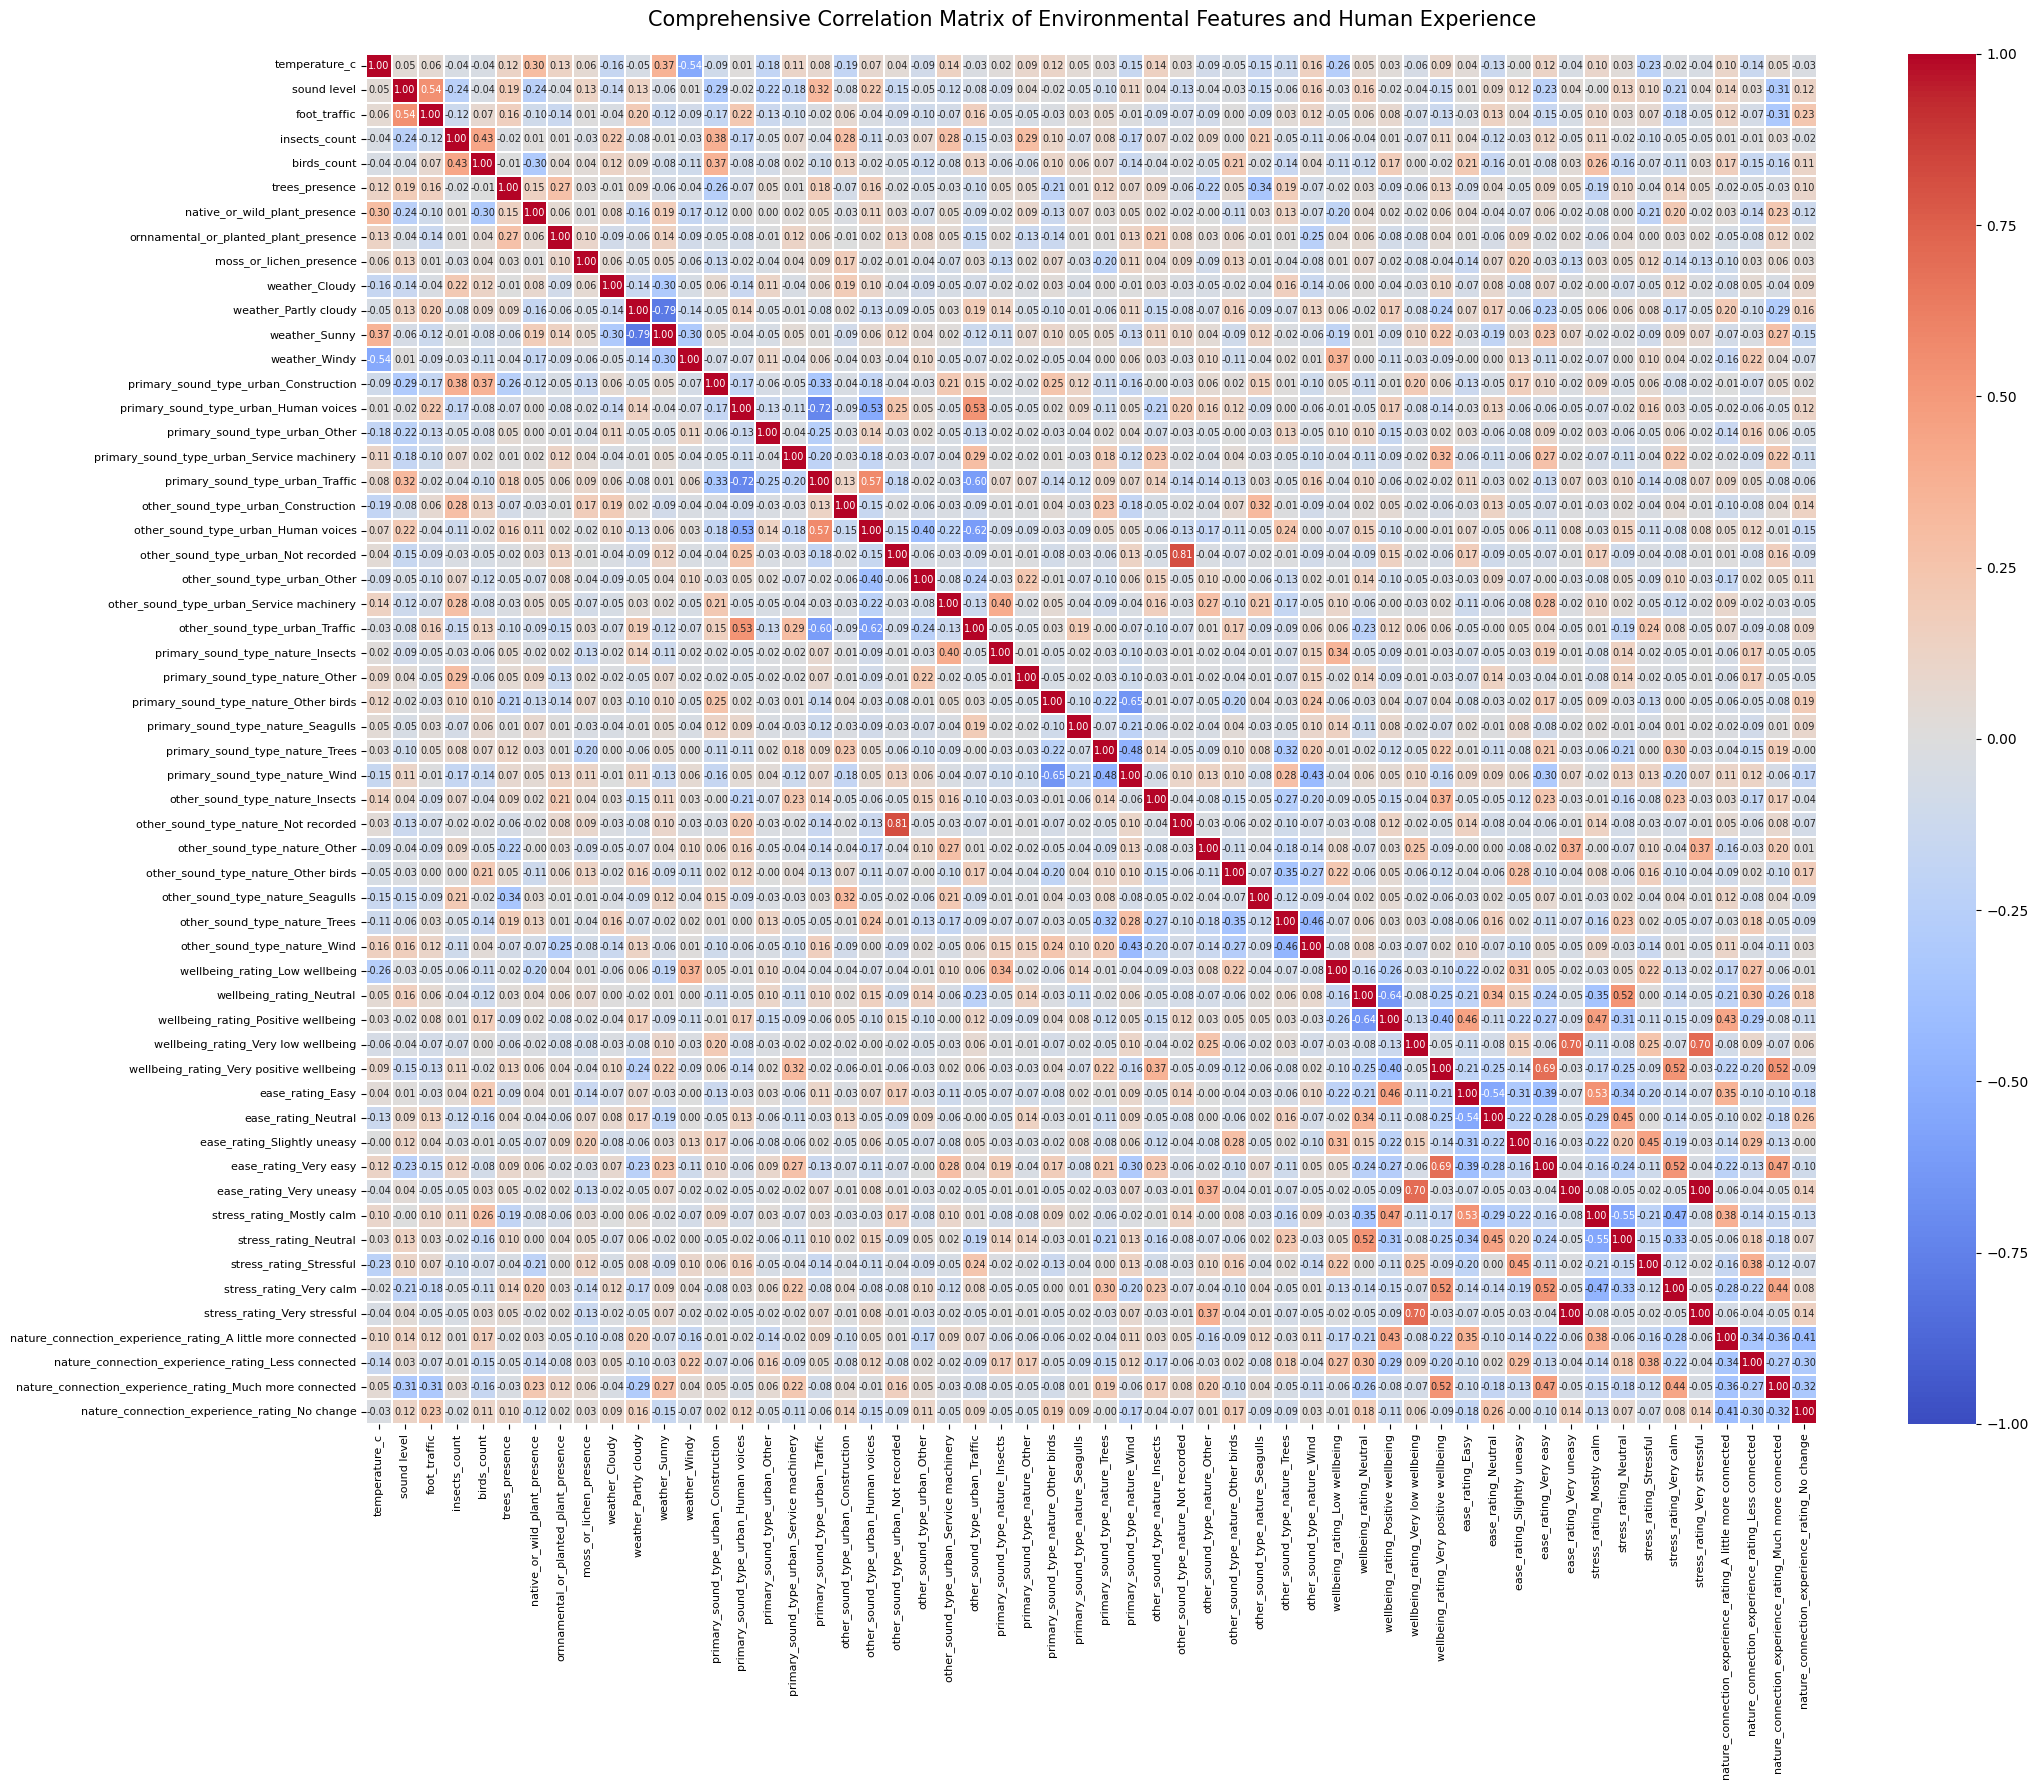

In [171]:

# Encode the four human-experience outcomes
outcome_encoded = pd.get_dummies(
    df[outcome],
    dtype=int
)

# Combine encoded environmental features and outcomes
correlation_data = pd.concat(
    [X, outcome_encoded],
    axis=1
)

# Calculate Pearson correlation matrix
correlation_matrix = correlation_data.corr(method="pearson")

# Plot comprehensive correlation heatmap
plt.figure(figsize=(22, 18))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    annot=True,
    fmt=".2f",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.3,
    annot_kws={"size": 7}
)

plt.title(
    "Comprehensive Correlation Matrix of Environmental Features and Human Experience",
    fontsize=15,
    pad=20
)

plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)

plt.tight_layout()
plt.show()

In [172]:
# @title Data info

# Combine environmental and outcome variables
selected_features = features + outcome

# Inspect data types and missing values
quality_check = pd.DataFrame({
    "Data Type": df[selected_features].dtypes,
    "Missing Values": df[selected_features].isnull().sum(),
    "Unique Values": df[selected_features].nunique()
})

display(quality_check)

,Data Type,Missing Values,Unique Values
weather,object,0,4
temperature_c,Float64,0,9
sound level,object,0,3
foot_traffic,object,0,3
primary_sound_type_urban,object,0,5
other_sound_type_urban,object,3,5
primary_sound_type_nature,object,0,6
other_sound_type_nature,object,2,6
insects_count,int64,0,13
birds_count,int64,0,11


In [173]:
# @title Display table
display(df)

,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,...,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes
0,R26_001,22/09/2026,L01 MainEntrance,Partly cloudy,16.0,Quiet,Low,Human voices,Traffic,Wind,...,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,<NA>
1,R26_001,22/09/2026,L02 LibraryGreen,Sunny,16.0,Moderate,Low,Traffic,Human voices,Wind,...,Many,None,Some,None,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,<NA>
2,R26_001,22/09/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16.0,Quiet,Low,Construction,Traffic,Wind,...,Many,None,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,<NA>
3,R26_001,22/09/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16.0,Moderate,Low,Human voices,Human voices,Wind,...,One or two,Some,None,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,<NA>
4,R26_001,22/09/2026,L06 HedgingBehindSportsCentre,Sunny,16.0,Moderate,Low,Traffic,Other,Wind,...,One or two,None,Some,None,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
130,R26_027,23/09/2026,L04 PathFrontiHub,Windy,16.0,Quiet,Low,Traffic,Human voices,Trees,...,Many,Some,Some,None,Positive wellbeing,Easy,Mostly calm,Much more connected,Plants,N/A
131,R26_028,07/10/2026,L10 OtherOffCampus,Windy,10.0,Quiet,Low,Other,Human voices,Wind,...,One or two,None,None,None,Neutral,Easy,Mostly calm,Less connected,Trees,<NA>
132,R26_028,07/10/2026,L10 OtherOffCampus,Windy,10.0,Moderate,Low,Traffic,Other,Wind,...,Many,Many,None,Some,Positive wellbeing,Easy,Very calm,Much more connected,plants,<NA>
133,R26_028,07/10/2026,L01 MainEntrance,Partly cloudy,15.0,Moderate,Moderate,Traffic,Construction,Other birds,...,Many,Some,None,Many,Positive wellbeing,Neutral,Neutral,No change,grass,<NA>
